<a href="https://colab.research.google.com/github/xtianu/UPC_DAPR_2026/blob/main/S2/Exercises/S2_1_Exercises_Data_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **S2. DATA VISUALIZATION**

**PRACTICE EXERCISES**

This notebook contains 3 exercises to practice pandas data handling and seaborn/matplotlib visualization. To keep things simple and avoid uploading files, all exercises use datasets built into seaborn (`sns.load_dataset(...)`), which download automatically the first time you run them.

Complete the code in the cells marked with `# YOUR CODE HERE`.


---

## Exercise 1: Handling data and missing values — Penguins dataset

Load the built-in `penguins` dataset from seaborn:

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

Answer the following questions:

a) How many rows and columns does the dataset have? (`.shape`)

b) How many observations have a missing value in the `body_mass_g` column? (use `.isna()`, as seen with the Titanic `Age` column)

c) Create a new dataframe `penguins_filled` where the missing values of `body_mass_g` are replaced with the **mean** of the column (`.fillna()`).

d) Using `.groupby()`, compute the mean `body_mass_g` and `flipper_length_mm` **per species** (`species` column).

e) Filter the dataset to show only penguins of species `"Gentoo"` with `body_mass_g` greater than 5000 (combine two conditions with `&`, as done with the Titanic `Humans`/`Robots` example).

In [2]:
import seaborn as sns
import pandas as pd

penguins = sns.load_dataset('penguins')
penguins.head()

# a) YOUR CODE HERE: shape of the dataset
print(penguins.shape)

# b) YOUR CODE HERE: count missing values in 'body_mass_g'
print(penguins.shape[0] - penguins.body_mass_g.count())

# c) YOUR CODE HERE: create penguins_filled with missing body_mass_g replaced by the mean
penguins_filled = penguins
penguins_filled.body_mass_g = penguins.body_mass_g.fillna(penguins.body_mass_g.mean())

# d) YOUR CODE HERE: mean body_mass_g and flipper_length_mm grouped by species
# print(penguins_filled.head())
print(penguins_filled[["species", "body_mass_g", "flipper_length_mm"]].groupby(["species"]).mean())

# e) YOUR CODE HERE: filter Gentoo penguins with body_mass_g > 5000
gentoo_heavy = penguins.query('body_mass_g <= 5000')
print(gentoo_heavy.body_mass_g.mean())


(344, 7)
2
           body_mass_g  flipper_length_mm
species                                  
Adelie     3703.958910         189.953642
Chinstrap  3733.088235         195.823529
Gentoo     5068.965761         217.186992
3921.567168805406


---

## Exercise 2: Basic and grouped plots — Tips dataset

Load the built-in `tips` dataset from seaborn:

```python
tips = sns.load_dataset('tips')
```

This dataset contains information about restaurant bills: `total_bill`, `tip`, `sex`, `smoker`, `day`, `time`, `size`.

Create the following plots (remember to set `figsize`, add a title with `.set_title()`, and call `plt.show()`):

a) A **scatter plot** of `total_bill` (x-axis) vs `tip` (y-axis).

b) The same scatter plot, but colored by `smoker` status using the `hue` parameter (like the `origin` example with cars).

c) A **linear model plot** (`sns.lmplot`) of `total_bill` vs `tip`, separated by `time` (Lunch/Dinner) using `hue`.

d) A **bar plot** showing the average `tip` for each `day` of the week.

e) A **histogram** (`sns.distplot` or `sns.histplot`) of the `total_bill` column, and mark the **mean** value with a vertical dashed line (`plt.axvline`).

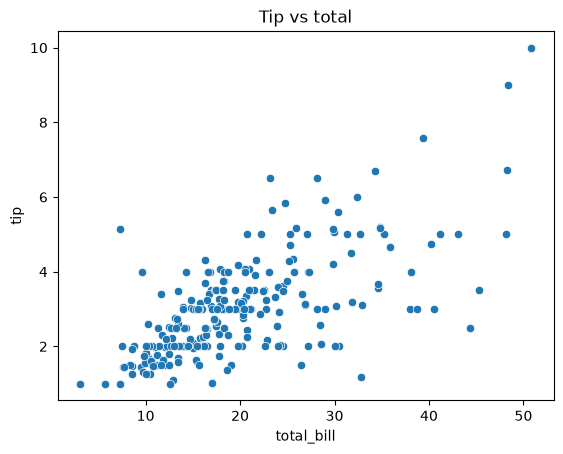

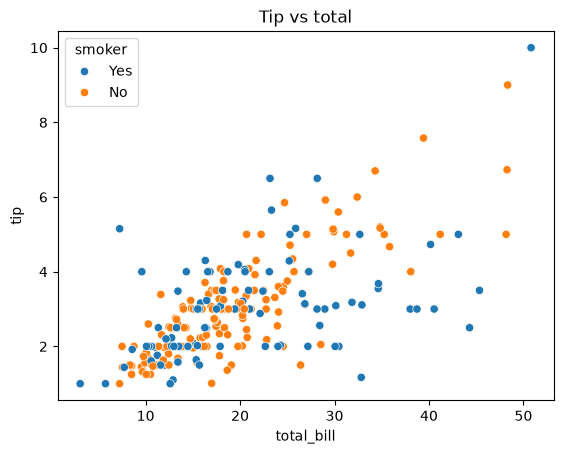

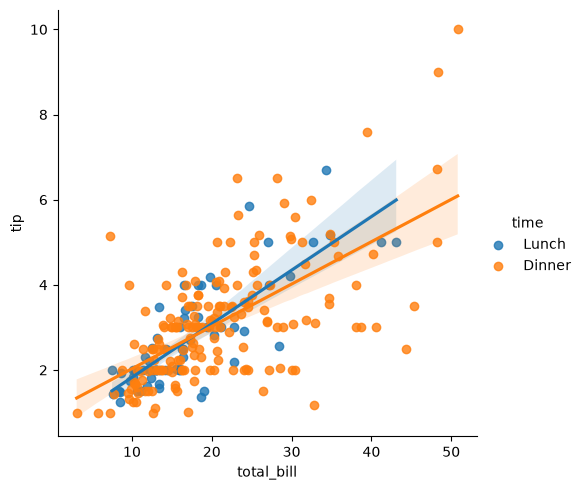

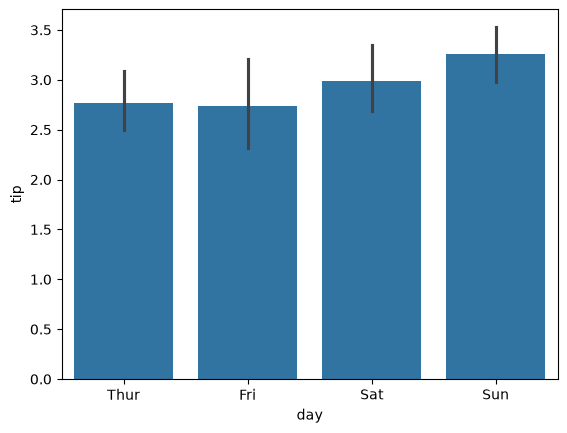

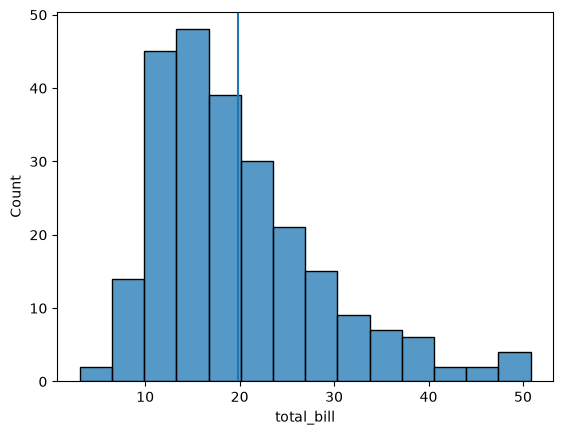

In [3]:
import matplotlib.pyplot as plt

tips = sns.load_dataset('tips')
tips.head()

# a) YOUR CODE HERE: scatter plot total_bill vs tip
# fig = plt.figure(figsize=(10,6))
ax = sns.scatterplot(tips, x="total_bill", y="tip")
ax.set_title("Tip vs total")
plt.show()

# b) YOUR CODE HERE: same scatter plot colored by 'smoker'
ax = sns.scatterplot(tips, x="total_bill", y="tip", hue="smoker")
ax.set_title("Tip vs total")
plt.show()
# c) YOUR CODE HERE: lmplot of total_bill vs tip, hue='time'
ax = sns.lmplot(tips, x="total_bill", y="tip", hue="time")
plt.show()

# d) YOUR CODE HERE: bar plot of average tip per day
ax = sns.barplot(tips, x="day", y="tip", estimator="average")
plt.show()

# e) YOUR CODE HERE: histogram of total_bill with a vertical line at the mean
ax = sns.histplot(tips, x="total_bill")
ax.axvline(tips.total_bill.mean())
plt.show()

---

## Exercise 3: Distributions and multidimensional relationships — Diamonds dataset

Load the built-in `diamonds` dataset from seaborn (it's large, so we take a random sample of 1000 rows to keep the plots fast):

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

This dataset contains information about diamonds: `carat`, `cut`, `color`, `clarity`, `depth`, `table`, `price`, and dimensions `x`, `y`, `z`.

a) Get a statistical summary of the numeric variables with `.describe()`.

b) Create a **histogram** of the `price` variable and mark the mean (dashed line) and the mean ± one standard deviation (two more vertical lines), as done with the `weight` variable of the cars dataset.

c) Create a **joint distribution plot** (`sns.jointplot`) between `carat` and `price`.

d) Create a **pairplot** (`sns.pairplot`) using only the numeric columns `carat`, `depth`, `table`, `price`, colored by the `cut` category with `hue`.

e) Based on the plots above, write one sentence (in a markdown cell or as a Python comment) describing the relationship you observe between `carat` and `price`.

             carat        depth        table         price           x  \
count  1000.000000  1000.000000  1000.000000   1000.000000  1000.00000   
mean      0.827500    61.759700    57.368800   4165.147000     5.80121   
std       0.490193     1.401489     2.303578   4190.104476     1.14740   
min       0.230000    55.200000    53.000000    360.000000     3.89000   
25%       0.410000    61.100000    56.000000   1007.000000     4.74000   
50%       0.710000    61.900000    57.000000   2542.500000     5.74500   
75%       1.080000    62.500000    59.000000   5569.750000     6.60000   
max       2.750000    68.400000    73.000000  18803.000000     9.04000   

                 y            z  
count  1000.000000  1000.000000  
mean      5.800870     3.580360  
std       1.142003     0.700021  
min       3.930000     2.430000  
25%       4.750000     2.950000  
50%       5.750000     3.550000  
75%       6.600000     4.060000  
max       8.980000     5.490000  


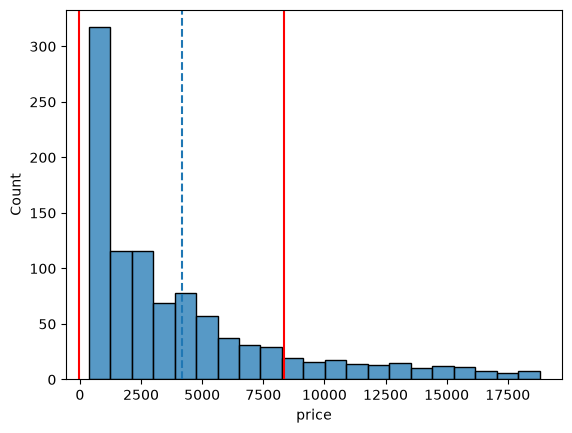

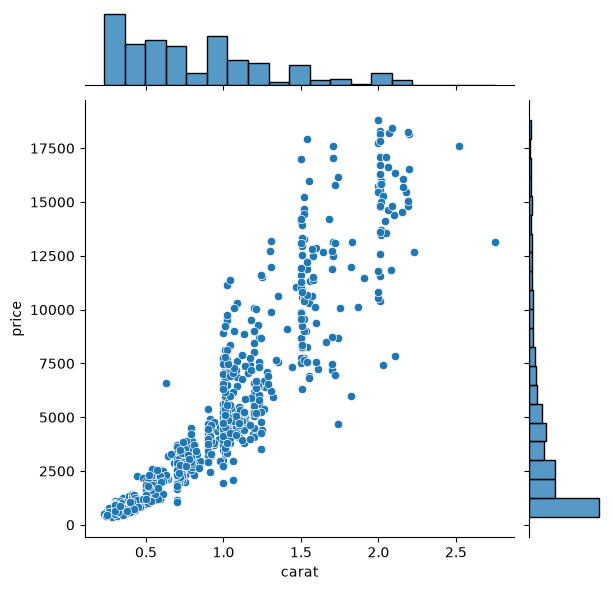

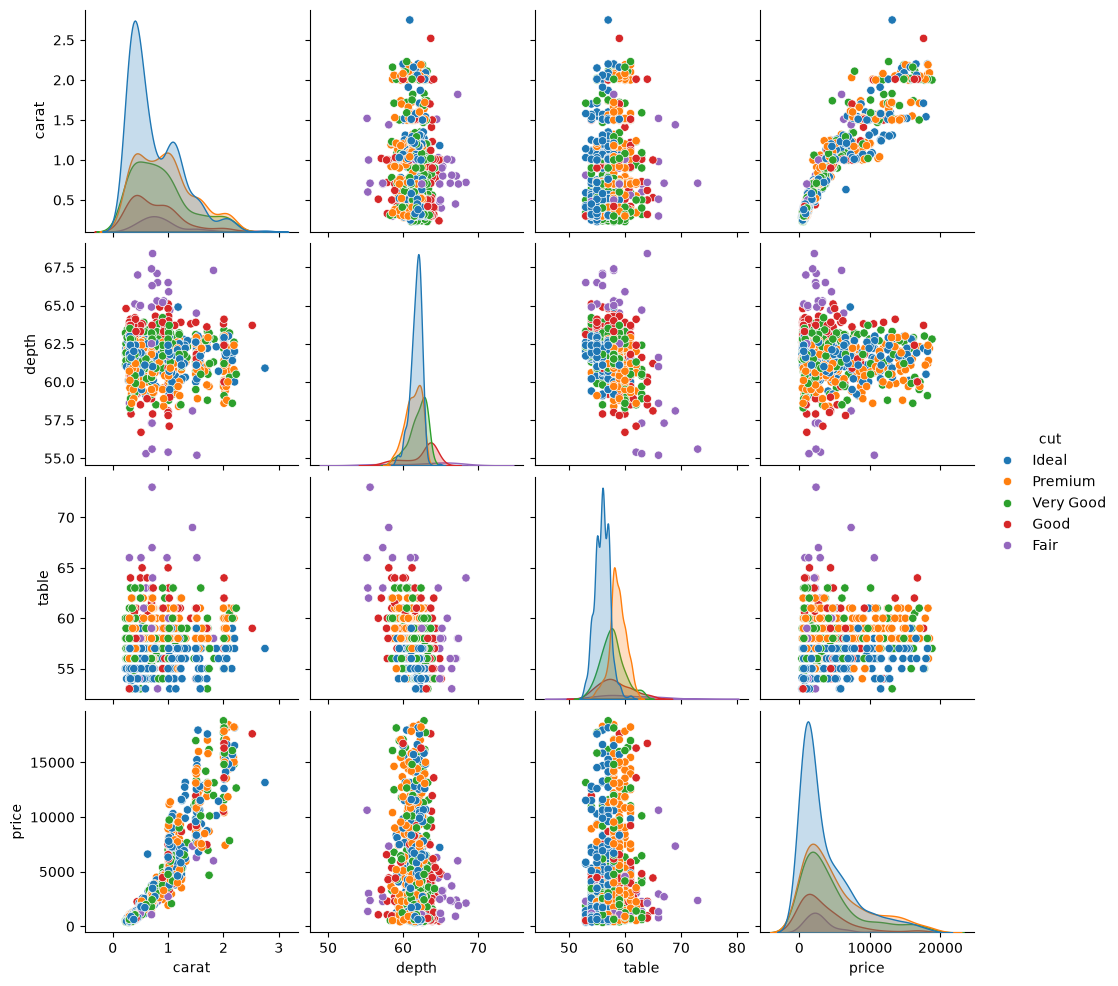

In [ ]:
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
diamonds.head()

# a) YOUR CODE HERE: statistical summary
print(diamonds.describe())

# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines
ax = sns.histplot(diamonds.price)
ax.axvline(diamonds.price.mean(), linestyle="--")
ax.axvline(diamonds.price.mean() + diamonds.price.std(), linestyle="-", color="red")
ax.axvline(diamonds.price.mean() - diamonds.price.std(), linestyle="-", color='red')
plt.show()

# c) YOUR CODE HERE: jointplot between carat and price
sns.jointplot(diamonds, x="carat", y="price")
plt.show()

# d) YOUR CODE HERE: pairplot of carat, depth, table, price, hue='cut'
sns.pairplot(diamonds.filter(["carat", "depth", "table", "price", "cut"]), hue="cut")
plt.show()

# e) YOUR CODE HERE (as a comment): describe the relationship between carat and price
# there is a positive corelation between the carats and the price of a diamond